# Fine-tune IndoBERT on coastSent and evaluate

This notebook fine-tunes the domain-adapted IndoBERT (DAPT) on the coastSent labeled dataset,
evaluates on both coastSent (source) and Lazada (target) test sets, and produces a t-SNE visualization
of encoder embeddings (source vs target). Adjust paths/parameters as needed.

In [1]:
# Imports
import os
import random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report
from sklearn.manifold import TSNE
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments, DataCollatorWithPadding

sns.set(style='whitegrid')

In [2]:
# Reproducibility and device
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


In [3]:
# Configuration - edit as needed
MODEL_DIR = '../../dapt_lazada/'  # domain-adapted IndoBERT (MLM)
OUTPUT_DIR = './models/indobert_telemedicine_finetuned'
BATCH_SIZE = 32
MAX_LENGTH = 128
EPOCHS = 3
LR = 1e-5
os.makedirs('outputs', exist_ok=True)
print('Config set')

Config set


In [4]:
# Label map and helpers
LABEL2ID = {'negative': 0, 'positive': 1}
ID2LABEL = {v:k for k,v in LABEL2ID.items()}

def resolve_text_column(df):
    for c in ['reviewContent','content','text','review']:
        if c in df.columns:
            return c
    raise ValueError('No text-like column found: ' + ','.join(df.columns))

def _normalize_labels(series):
    return series.astype(str).str.strip().str.lower().replace({
        'pos':     'positive', 'neg':     'negative',
        '1':       'positive', '0':       'negative',
        'positif': 'positive', 'negatif': 'negative',
        'true':    'positive', 'false':   'negative',
    })

In [5]:
# Load datasets
train_df = pd.read_csv('../../datasets/telemedicine_preprocessed/train.csv')
coast_test_df = pd.read_csv('../../datasets/telemedicine_preprocessed/test.csv')
lazada_test_df = pd.read_csv('../../datasets/lazada_test_preprocessed.csv')
print('Loaded shapes:', train_df.shape, coast_test_df.shape, lazada_test_df.shape)

Loaded shapes: (6696, 2) (1674, 2) (2042, 2)


In [6]:
# Clean and prepare labels/text
text_col = resolve_text_column(train_df)
for df in (train_df, coast_test_df, lazada_test_df):
    tc = resolve_text_column(df)
    df[tc] = df[tc].astype(str).str.strip()
    if 'label' in df.columns:
        df['label'] = _normalize_labels(df['label'])

train_df = train_df.dropna(subset=[text_col])
train_df = train_df[train_df[text_col] != '']
train_df['label_id'] = train_df['label'].map(LABEL2ID)
train_df = train_df.dropna(subset=['label_id'])

coast_test_df['label_id'] = coast_test_df['label'].map(LABEL2ID)
lazada_test_df['label_id'] = lazada_test_df['label'].map(LABEL2ID)

print('Train label counts:', train_df['label_id'].value_counts().to_dict())

Train label counts: {0: 3348, 1: 3348}


In [7]:
# Load tokenizer and classification model (adds head automatically)
tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR, num_labels=2, id2label=ID2LABEL, label2id=LABEL2ID, ignore_mismatched_sizes=True)
model.to(device)
print('Model and tokenizer loaded')

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at ../../dapt_lazada/ and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Model and tokenizer loaded


In [8]:
# Prepare HF datasets and tokenization
hf_train = Dataset.from_dict({'text': train_df[text_col].astype(str).tolist(), 'label': train_df['label_id'].tolist()})
split = hf_train.train_test_split(test_size=0.1, seed=42)
train_ds = split['train']
val_ds = split['test']

def tokenize_fn(examples):
    return tokenizer(examples['text'], truncation=True, max_length=MAX_LENGTH)

train_tok = train_ds.map(tokenize_fn, batched=True, remove_columns=['text'])
val_tok = val_ds.map(tokenize_fn, batched=True, remove_columns=['text'])
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
print('Datasets tokenized:', len(train_tok), len(val_tok))

Map:   0%|          | 0/6026 [00:00<?, ? examples/s]

Map:   0%|          | 0/670 [00:00<?, ? examples/s]

Datasets tokenized: 6026 670


In [9]:
# Training setup
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    acc = accuracy_score(labels, preds)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='weighted')
    return {'accuracy': acc, 'precision': precision, 'recall': recall, 'f1': f1}

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=LR,
    weight_decay=0.02,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='f1',
    logging_steps=50,
    fp16=torch.cuda.is_available(),
    report_to='none',
)

trainer = Trainer(model=model, args=training_args, train_dataset=train_tok, eval_dataset=val_tok, data_collator=data_collator, compute_metrics=compute_metrics)
print('Trainer ready')

Trainer ready


In [10]:
# Train (can take time) - reduce EPOCHS for a quick smoke test
train_result = trainer.train()
print(train_result.metrics)
trainer.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)
print('Saved model to', OUTPUT_DIR)

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.167700,0.151311,0.953731,0.953973,0.953731,0.953748
2,0.143500,0.158502,0.952239,0.952548,0.952239,0.952258
3,0.108500,0.174945,0.944776,0.945779,0.944776,0.944804


{'train_runtime': 59.4021, 'train_samples_per_second': 304.333, 'train_steps_per_second': 9.545, 'total_flos': 708173683277040.0, 'train_loss': 0.1631043400924252, 'epoch': 3.0}
Saved model to ./models/indobert_telemedicine_finetuned


In [11]:
# Evaluation helper
def eval_on_df(df, name='eval'):
    tc = resolve_text_column(df)
    d = df.copy()
    d['label_id'] = d['label'].map(LABEL2ID)
    ds = Dataset.from_dict({'text': d[tc].astype(str).tolist(), 'label': d['label_id'].tolist()})
    tok = ds.map(tokenize_fn, batched=True, remove_columns=['text'])
    pred = trainer.predict(tok)
    preds = np.argmax(pred.predictions, axis=1)
    labels = pred.label_ids
    print(f'\nEvaluation on {name} - samples: {len(labels)}')
    print(classification_report(labels, preds, target_names=['negative','positive'], digits=4))
    acc = accuracy_score(labels, preds)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='weighted')
    return {'accuracy': acc, 'precision': precision, 'recall': recall, 'f1': f1}

src_res = eval_on_df(coast_test_df, name='coast_test (source)')
tgt_res = eval_on_df(lazada_test_df, name='lazada_test (target)')
print('SUMMARY')
for k in ['accuracy','precision','recall','f1']:
    print(f'{k}: source={src_res[k]:.4f}  target={tgt_res[k]:.4f}  gap={src_res[k]-tgt_res[k]:+.4f}')

Map:   0%|          | 0/1674 [00:00<?, ? examples/s]


Evaluation on coast_test (source) - samples: 1674
              precision    recall  f1-score   support

    negative     0.9474    0.9247    0.9359       837
    positive     0.9265    0.9486    0.9374       837

    accuracy                         0.9367      1674
   macro avg     0.9369    0.9367    0.9367      1674
weighted avg     0.9369    0.9367    0.9367      1674



Map:   0%|          | 0/2042 [00:00<?, ? examples/s]


Evaluation on lazada_test (target) - samples: 2042
              precision    recall  f1-score   support

    negative     0.8889    0.7529    0.8153      1020
    positive     0.7861    0.9061    0.8418      1022

    accuracy                         0.8296      2042
   macro avg     0.8375    0.8295    0.8286      2042
weighted avg     0.8374    0.8296    0.8286      2042

SUMMARY
accuracy: source=0.9367  target=0.8296  gap=+0.1071
precision: source=0.9369  target=0.8374  gap=+0.0995
recall: source=0.9367  target=0.8296  gap=+0.1071
f1: source=0.9367  target=0.8286  gap=+0.1081


Map:   0%|          | 0/1674 [00:00<?, ? examples/s]

Map:   0%|          | 0/2042 [00:00<?, ? examples/s]

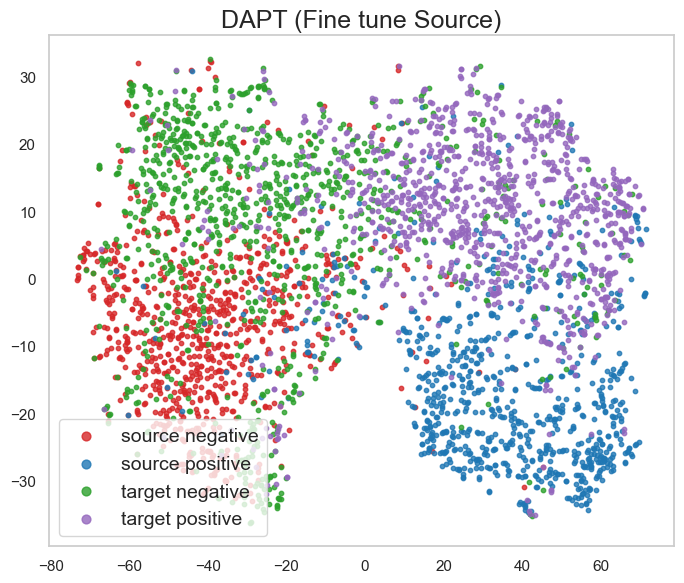

Saved t-SNE visualization to: outputs/tsne_coastsent_vs_lazada.png


In [12]:
# Extract encoder embeddings (mean-pooled) and plot t-SNE
import seaborn as sns
from sklearn.decomposition import PCA
from torch.utils.data import DataLoader
sns.set(style='whitegrid')

def extract_embeddings_from_dataloader(model, dataloader, device, stage='encoder'):
    """Extract embeddings from a dataloader for a given stage."""
    model.eval()
    Xs = []
    Ys = []

    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            
            # Extract mean-pooled features from base model
            base = getattr(model, 'base_model', model)
            o = base(input_ids=input_ids, attention_mask=attention_mask)
            h = o.last_hidden_state
            mask = attention_mask.unsqueeze(-1).float()
            feats = (h * mask).sum(1) / mask.sum(1).clamp(min=1e-9)
            
            Xs.append(feats.cpu().numpy())
            
            # Extract labels - handle both tensor and missing cases
            if 'label_id' in batch:
                label_id = batch['label_id']
                if isinstance(label_id, torch.Tensor):
                    Ys.append(label_id.cpu().numpy())
                else:
                    Ys.append(np.array(label_id))
            else:
                Ys.append(np.full((feats.size(0),), -1, dtype=int))

    if len(Xs) == 0:
        return np.zeros((0, model.config.hidden_size)), np.array([])

    X = np.concatenate(Xs, axis=0)
    Y = np.concatenate(Ys, axis=0)
    return X, Y

def project_embeddings(X, method='tsne', n_components=2, random_state=42):
    """Project embeddings to 2D using t-SNE or PCA."""
    if X.shape[0] == 0:
        return X
    
    if method == 'tsne':
        if X.shape[1] > 50:
            p = PCA(n_components=50, random_state=random_state).fit_transform(X)
        else:
            p = X
        ts = TSNE(n_components=n_components, random_state=random_state, init='pca', perplexity=30)
        return ts.fit_transform(p)

    pca = PCA(n_components=n_components, random_state=random_state)
    return pca.fit_transform(X)

def plot_single_panel(proj, labels, domains, title, outpath=None, figsize=(7, 6)):
    """Plot a single projection panel with legend for domain+label combinations."""
    palette = {
        ('source', 0): '#d62728',
        ('source', 1): '#1f77b4',
        ('target', 0): '#2ca02c',
        ('target', 1): '#9467bd',
    }
    display_names = {
        ('source', 0): 'source negative',
        ('source', 1): 'source positive',
        ('target', 0): 'target negative',
        ('target', 1): 'target positive',
    }
    plot_order = [('source', 0), ('source', 1), ('target', 0), ('target', 1)]

    fig, ax = plt.subplots(1, 1, figsize=figsize)
    domains_np = np.array(domains)
    
    xs, ys = proj[:, 0], proj[:, 1]
    for dom, lab in plot_order:
        mask = (domains_np == dom) & (labels == lab)
        if mask.sum() == 0:
            continue
        ax.scatter(
            xs[mask],
            ys[mask],
            s=10,
            c=palette[(dom, lab)],
            label=display_names[(dom, lab)],
            alpha=0.8,
        )

    ax.set_title(title, fontsize=18)
    ax.grid(False)
    ax.legend(loc='lower left', fontsize=14, frameon=True, markerscale=2)

    fig.tight_layout()
    if outpath:
        os.makedirs(os.path.dirname(outpath), exist_ok=True)
        fig.savefig(outpath, dpi=200)
    plt.show()

# Prepare loaders for embeddings extraction
hf_coast_test = Dataset.from_dict({
    'text': coast_test_df[resolve_text_column(coast_test_df)].astype(str).tolist(),
    'label_id': coast_test_df['label_id'].astype(int).tolist()
})
hf_lazada_test = Dataset.from_dict({
    'text': lazada_test_df[resolve_text_column(lazada_test_df)].astype(str).tolist(),
    'label_id': lazada_test_df['label_id'].astype(int).tolist()
})

def tokenize_fn_simple(examples):
    enc = tokenizer(examples['text'], truncation=True, max_length=MAX_LENGTH, padding=False)
    enc['label_id'] = examples['label_id']
    return enc

coast_test_tok = hf_coast_test.map(tokenize_fn_simple, batched=True, remove_columns=['text'])
lazada_test_tok = hf_lazada_test.map(tokenize_fn_simple, batched=True, remove_columns=['text'])

# Use DataCollatorWithPadding for proper tensor conversion
collator = DataCollatorWithPadding(tokenizer=tokenizer)

src_loader = DataLoader(coast_test_tok, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collator)
tgt_loader = DataLoader(lazada_test_tok, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collator)

# Extract embeddings
Xs_src, Ys_src = extract_embeddings_from_dataloader(trainer.model, src_loader, device, stage='encoder')
Xs_tgt, Ys_tgt = extract_embeddings_from_dataloader(trainer.model, tgt_loader, device, stage='encoder')

# Concatenate and project
X = np.concatenate([Xs_src, Xs_tgt], axis=0)
Y = np.concatenate([Ys_src, Ys_tgt], axis=0)
domains = np.array(['source'] * Xs_src.shape[0] + ['target'] * Xs_tgt.shape[0])

proj = project_embeddings(X, method='tsne', n_components=2, random_state=42)

outpath = 'outputs/tsne_coastsent_vs_lazada.png'
plot_single_panel(proj, Y, domains, title='DAPT (Fine tune Source)', outpath=outpath, figsize=(7, 6))
print(f'Saved t-SNE visualization to: {outpath}')